In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Local onde está armazenado o conjunto de dados
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
# Carregando arquivo CSV e transformando o dados em um DataFrame
df = pd.read_csv(url)
# Visualização das primeira 5 linhas
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Verificar a quantidade de linhas e colunas da tabela
df.shape

(284807, 31)

In [4]:
# Exibe o nome de todas as colunas da tabela
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [5]:
## Exibe informações sobre a estrutura do DataFrame
# Incluindo tipos das variáveis e quantidade de valores não nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [6]:
## Usaria caso tivesse valores nulos
# df.dropna()

In [7]:
# Contar os valores que aparecem em Class
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [8]:
# Proporção de cada valor dentro de Class 
df['Class'].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [9]:
## Usaria df.duplicated() para indicar descritivamente quais linhas estariam ou não duplicadas
# True para duplicada / False para não duplicada
# df.duplicated()

In [10]:
# Somar a quantidade total de True ou seja de linhas duplicadas
df.duplicated().sum()

np.int64(1081)

Como se trata de fraude não posso executar de cara um 'df.drop_duplicates()', já que duas transações podem ter caracteristicas identicas e ainda serem transações distintas

In [11]:
# Filtra somente os registros duplicados
duplicados = df[df.duplicated()]
# Identifica e conta as classes presentes entre os duplicados
duplicados['Class'].value_counts()

Class
0    1062
1      19
Name: count, dtype: int64

In [12]:
# Criação de uma cópia para que o arquivo original não seja alterado
# limpeza e transformações sem alterar os dados carregados originalmente
df_clean = df.copy()

In [13]:
## Remoção de registros completamente duplicados
# Isso vai evitar redundância e possivel vazamento entre treino e test
df_clean = df_clean.drop_duplicates()
# Conferência do novo tamanho da tabela
df_clean.shape

(283726, 31)

In [14]:
# Verificação da quantidade de transações legitimas e fraudulentas,
# após remoção dos duplicados
df_clean['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [15]:
# Proporção de cada valor dentro de Class  após a limpeza
df_clean['Class'].value_counts(normalize=True) * 100

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

In [16]:
# Obtenção de estatisticas descritivas
df_clean['Amount'].describe()

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

In [17]:
# Agrupar por Class, pega o Amount e descreve estatisticamente cada grupo
df_clean.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


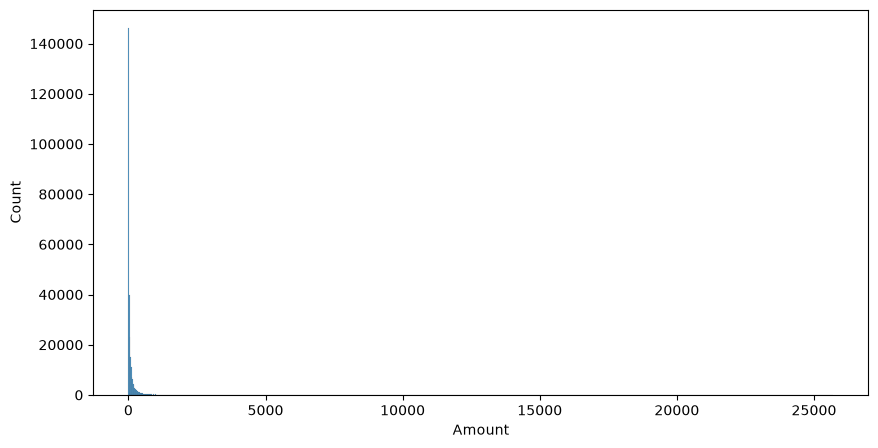

In [18]:
# Criação de um histograma para verificar como os valores "Amount" estão distribuidos
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x='Amount'
)
plt.show()

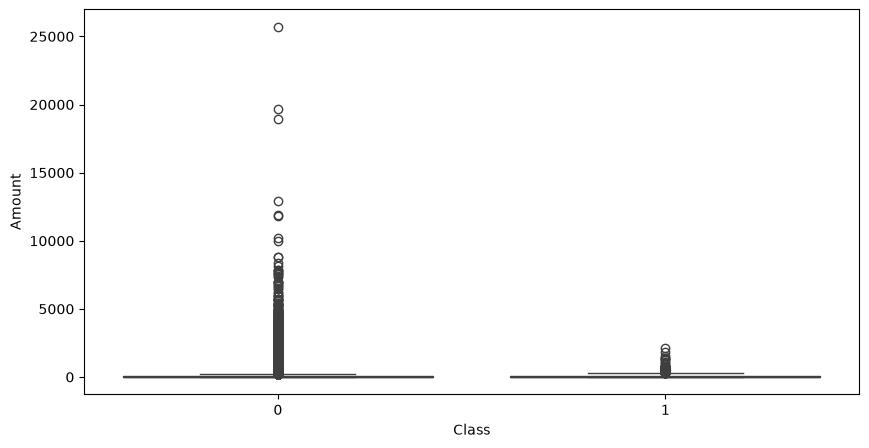

In [19]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_clean,
    x='Class',
    y='Amount'
)
plt.show()

In [20]:
df_clean.corr()['Class']

Time     -0.012359
V1       -0.094486
V2        0.084624
V3       -0.182322
V4        0.129326
V5       -0.087812
V6       -0.043915
V7       -0.172347
V8        0.033068
V9       -0.094021
V10      -0.206971
V11       0.149067
V12      -0.250711
V13      -0.003897
V14      -0.293375
V15      -0.003300
V16      -0.187186
V17      -0.313498
V18      -0.105340
V19       0.033631
V20       0.021486
V21       0.026357
V22       0.004887
V23      -0.006333
V24      -0.007210
V25       0.003202
V26       0.004265
V27       0.021892
V28       0.009682
Amount    0.005777
Class     1.000000
Name: Class, dtype: float64

In [21]:
# Calcula a correlação de cada variável com Class
correlation_class = df_clean.corr()["Class"]

# Ordena as correlações pela intensidade da relação,
# independentemente de serem positivas ou negativas
correlation_class.abs().sort_values(ascending=False)

Class     1.000000
V17       0.313498
V14       0.293375
V12       0.250711
V10       0.206971
V16       0.187186
V3        0.182322
V7        0.172347
V11       0.149067
V4        0.129326
V18       0.105340
V1        0.094486
V9        0.094021
V5        0.087812
V2        0.084624
V6        0.043915
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
Time      0.012359
V28       0.009682
V24       0.007210
V23       0.006333
Amount    0.005777
V22       0.004887
V26       0.004265
V13       0.003897
V15       0.003300
V25       0.003202
Name: Class, dtype: float64

In [22]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

In [23]:
from sklearn.model_selection import train_test_split

In [30]:
# Divide os dados em treino e teste mantendo
# a proporção das classes em ambos os conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y # Preserva a proporção das classes 
)

In [31]:
# Verificação da distribuição das classes nos dados de treino
y_train.value_counts(normalize=True) * 100

Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64

In [32]:
# Verificação das distribuição das classes nos dados de teste
y_test.value_counts(normalize=True) * 100

Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64

In [33]:
# Verifica a quantidade de cada classe no conjunto de treino
print(y_train.value_counts())

# Verifica a quantidade de cada classe no conjunto de teste
print(y_test.value_counts())

Class
0    226602
1       378
Name: count, dtype: int64
Class
0    56651
1       95
Name: count, dtype: int64


In [34]:
from sklearn.preprocessing import StandardScaler

In [35]:
# Padronizador que será ajustado aos dados de treino
scaler = StandardScaler()

In [36]:
# Aprende a média e o desvio padrão do treino
# Transforma os dados de treinamento
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
from sklearn.linear_model import LogisticRegression

In [42]:
# Criação do modelo de Regressão Logistica
model = LogisticRegression(max_iter=1000)
# Treinamento e ajuste do modelo aos dados
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [43]:
# Previsões utilizando os dados de teste
y_pred = model.predict(X_test_scaled)

In [44]:
from sklearn.metrics import confusion_matrix

In [45]:
# Comparação de valores reais com previsões do modelo
confusion_matrix(y_test, y_pred)

array([[56641,    10],
       [   40,    55]])

In [47]:
from sklearn.metrics import classification_report
# Exibe as principais métrica de classificação
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



In [48]:
# Calcula a probabilidade de cada transação pertencer à classe fraude
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score

In [50]:
# Avalia a capacidade do modelo de separar transações legitimas de fraudulentas
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9560466717268892
